# 01. 데이터 준비 및 탐색적 데이터 분석 (EDA)
- 데이터셋: Kaggle **Titanic - Machine Learning from Disaster** (`train.csv`, 891행)
- 타겟: `Survived` (0 = 사망, 1 = 생존) → 이진 분류
- Kaggle `test.csv`는 정답이 없으므로 사용하지 않고, `train.csv`를 train/test로 분할한다.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.fe_pipeline import add_features

FIG = "../results/figures"
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

df = pd.read_csv("../data/train.csv")

## STEP 01. 데이터 구조 확인

In [2]:
print("data shape:", df.shape)
df.head()

data shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
col_desc = pd.DataFrame({
    "column": df.columns,
    "description": ["승객 ID (식별자)", "생존 여부 (타겟)", "객실 등급 (1/2/3)", "이름 (호칭 포함)", "성별",
                    "나이", "동승한 형제·배우자 수", "동승한 부모·자녀 수", "티켓 번호", "운임",
                    "객실 번호", "승선 항구 (C/Q/S)"],
    "type": ["ID", "Target", "Numeric(ordinal)", "Text", "Categorical", "Numeric", "Numeric", "Numeric",
             "Text", "Numeric", "Text/Categorical", "Categorical"],
    "dtype": df.dtypes.astype(str).values,
    "n_missing": df.isna().sum().values,
    "n_unique": df.nunique().values,
    "used": ["X (식별자)", "Target", "O", "Title 추출", "O", "O", "O", "O", "X (고유값 과다)", "O",
             "HasCabin 추출", "O"],
})
col_desc.to_csv("../results/column_description.csv", index=False)
col_desc

,column,description,type,dtype,n_missing,n_unique,used
0,PassengerId,승객 ID (식별자),ID,int64,0,891,X (식별자)
1,Survived,생존 여부 (타겟),Target,int64,0,2,Target
2,Pclass,객실 등급 (1/2/3),Numeric(ordinal),int64,0,3,O
3,Name,이름 (호칭 포함),Text,str,0,891,Title 추출
4,Sex,성별,Categorical,str,0,2,O
5,Age,나이,Numeric,float64,177,88,O
6,SibSp,동승한 형제·배우자 수,Numeric,int64,0,7,O
7,Parch,동승한 부모·자녀 수,Numeric,int64,0,7,O
8,Ticket,티켓 번호,Text,str,0,681,X (고유값 과다)
9,Fare,운임,Numeric,float64,0,248,O


## STEP 02. EDA
### (1) 결측치 비율

Cabin       77.10
Age         19.87
Embarked     0.22
dtype: float64


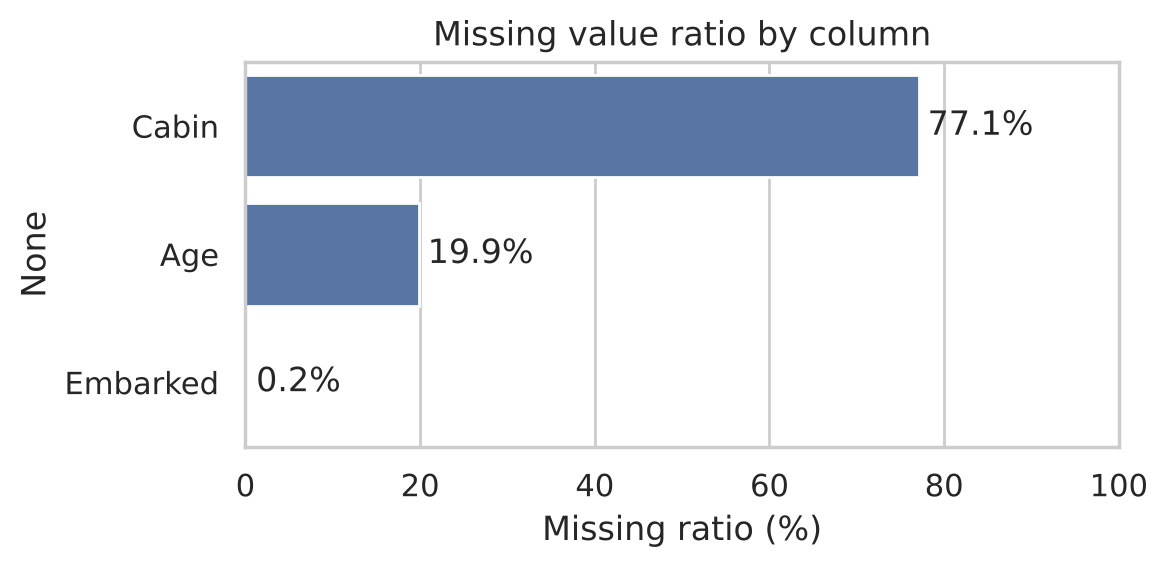

In [5]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(2))
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=miss.values, y=miss.index, ax=ax, color="#4C72B0")
for i, v in enumerate(miss.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlabel("Missing ratio (%)"); ax.set_title("Missing value ratio by column"); ax.set_xlim(0, 100)
plt.tight_layout(); plt.savefig(f"{FIG}/01_missing_ratio.png", dpi=150); plt.show()

### (2) 타겟 분포 (불균형 여부)

Survived
0    549
1    342
Name: count, dtype: int64 
 Survived
0    61.6
1    38.4
Name: count, dtype: float64


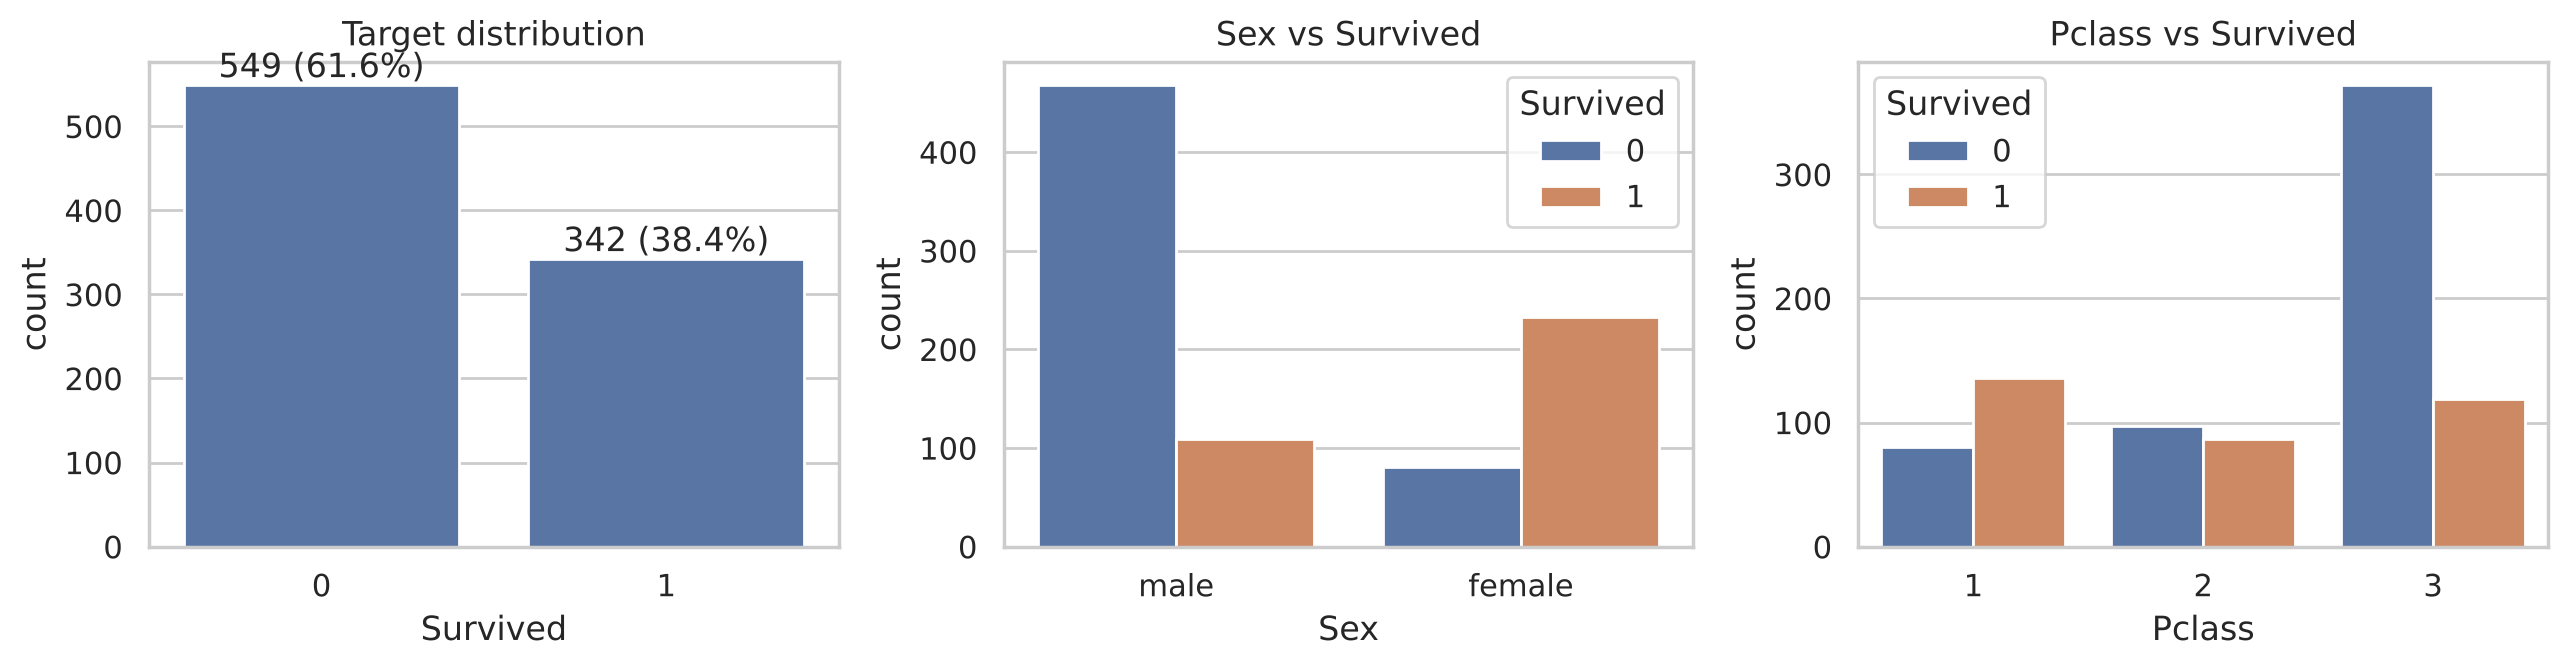

In [6]:
vc = df["Survived"].value_counts().sort_index()
print(vc, "\n", (vc / len(df) * 100).round(1))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.countplot(data=df, x="Survived", ax=axes[0], color="#4C72B0"); axes[0].set_title("Target distribution")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
sns.countplot(data=df, x="Sex", hue="Survived", ax=axes[1]); axes[1].set_title("Sex vs Survived")
sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[2]); axes[2].set_title("Pclass vs Survived")
plt.tight_layout(); plt.savefig(f"{FIG}/02_countplot_target.png", dpi=150); plt.show()

In [7]:
print(df.groupby("Sex")["Survived"].mean().round(3))
print(df.groupby("Pclass")["Survived"].mean().round(3))
print(df.groupby("Embarked")["Survived"].mean().round(3))

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64
Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64


### (3) 수치형 변수 분포 (Histogram)

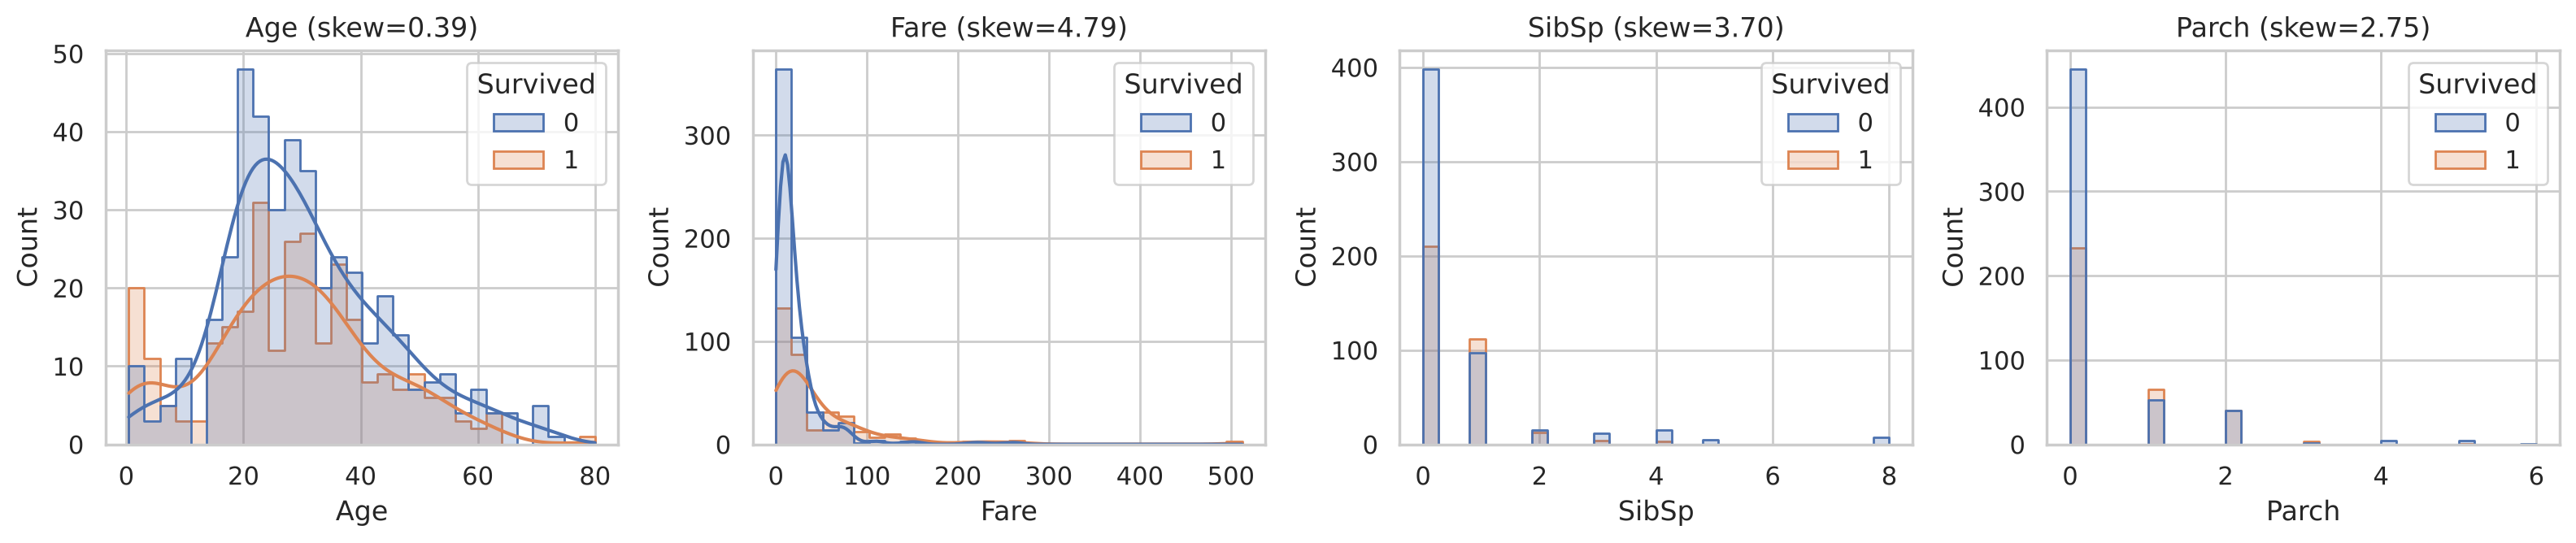

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, ["Age", "Fare", "SibSp", "Parch"]):
    sns.histplot(data=df, x=c, hue="Survived", bins=30, kde=(c in ["Age", "Fare"]), ax=ax, element="step")
    ax.set_title(f"{c} (skew={df[c].skew():.2f})")
plt.tight_layout(); plt.savefig(f"{FIG}/03_histogram.png", dpi=150); plt.show()

### (4) 이상치 탐색 (Boxplot + IQR)

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in ["Age", "Fare", "SibSp", "Parch"]:
    n, lo, hi = iqr_outliers(df[c].dropna())
    rows.append({"column": c, "n_outliers": n, "ratio(%)": round(n / df[c].notna().sum() * 100, 1),
                 "lower": round(lo, 2), "upper": round(hi, 2), "max": df[c].max()})
outlier_tbl = pd.DataFrame(rows)
outlier_tbl.to_csv("../results/outliers_iqr.csv", index=False)
outlier_tbl

,column,n_outliers,ratio(%),lower,upper,max
0,Age,11,1.5,-6.69,64.81,80.0000
1,Fare,116,13.0,-26.72,65.63,512.3292
2,SibSp,46,5.2,-1.50,2.50,8.0000
3,Parch,213,23.9,0.00,0.00,6.0000


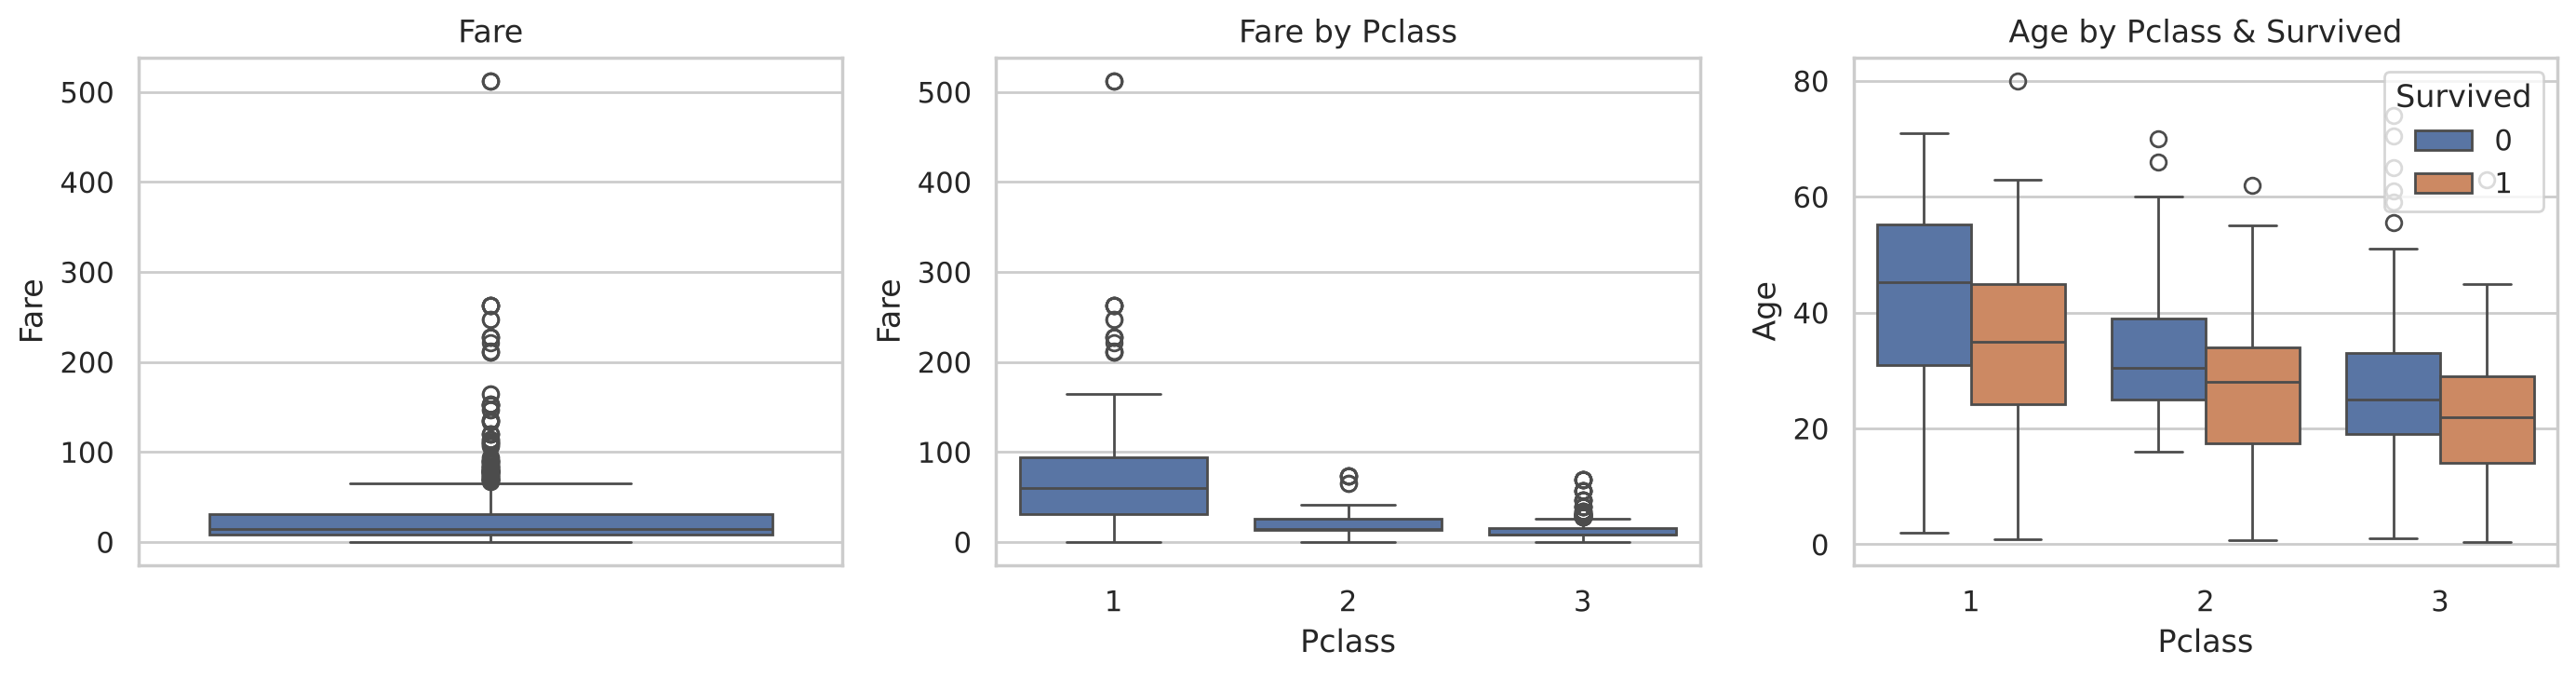

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.boxplot(data=df, y="Fare", ax=axes[0]); axes[0].set_title("Fare")
sns.boxplot(data=df, x="Pclass", y="Fare", ax=axes[1]); axes[1].set_title("Fare by Pclass")
sns.boxplot(data=df, x="Pclass", y="Age", hue="Survived", ax=axes[2]); axes[2].set_title("Age by Pclass & Survived")
plt.tight_layout(); plt.savefig(f"{FIG}/04_boxplot.png", dpi=150); plt.show()

### (5) 상관관계 분석 (Heatmap) — 파생 변수 포함

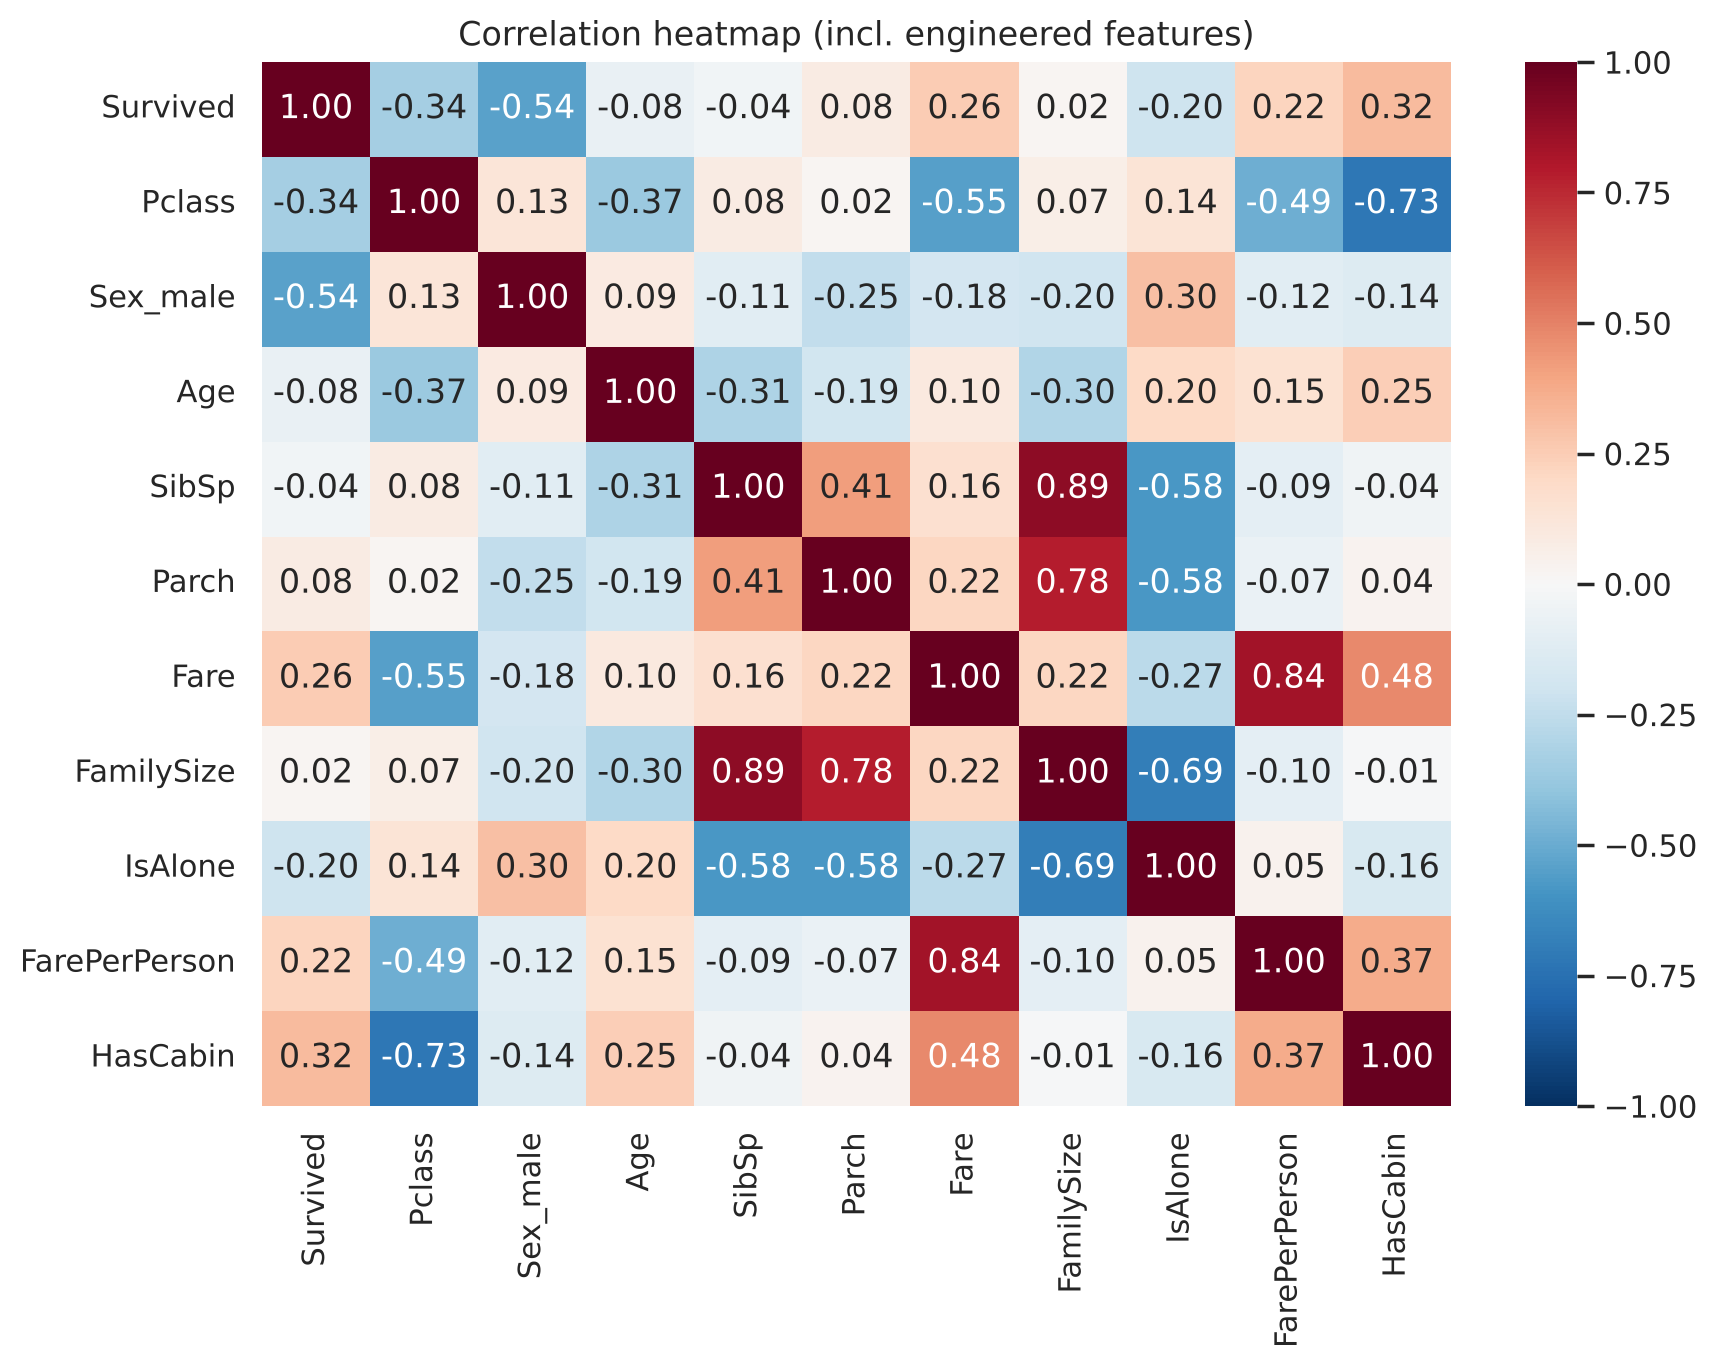

Sex_male        -0.543
Pclass          -0.338
HasCabin         0.317
Fare             0.257
FarePerPerson    0.222
IsAlone         -0.203
Parch            0.082
Age             -0.077
SibSp           -0.035
FamilySize       0.017
Name: Survived, dtype: float64


In [11]:
dfe = add_features(df)
dfe["Sex_male"] = (dfe["Sex"] == "male").astype(int)
corr_cols = ["Survived", "Pclass", "Sex_male", "Age", "SibSp", "Parch", "Fare",
             "FamilySize", "IsAlone", "FarePerPerson", "HasCabin"]
corr = dfe[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heatmap (incl. engineered features)")
plt.tight_layout(); plt.savefig(f"{FIG}/05_heatmap.png", dpi=150); plt.show()
print(corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3))

### (6) 파생 변수와 생존율 (Barplot)

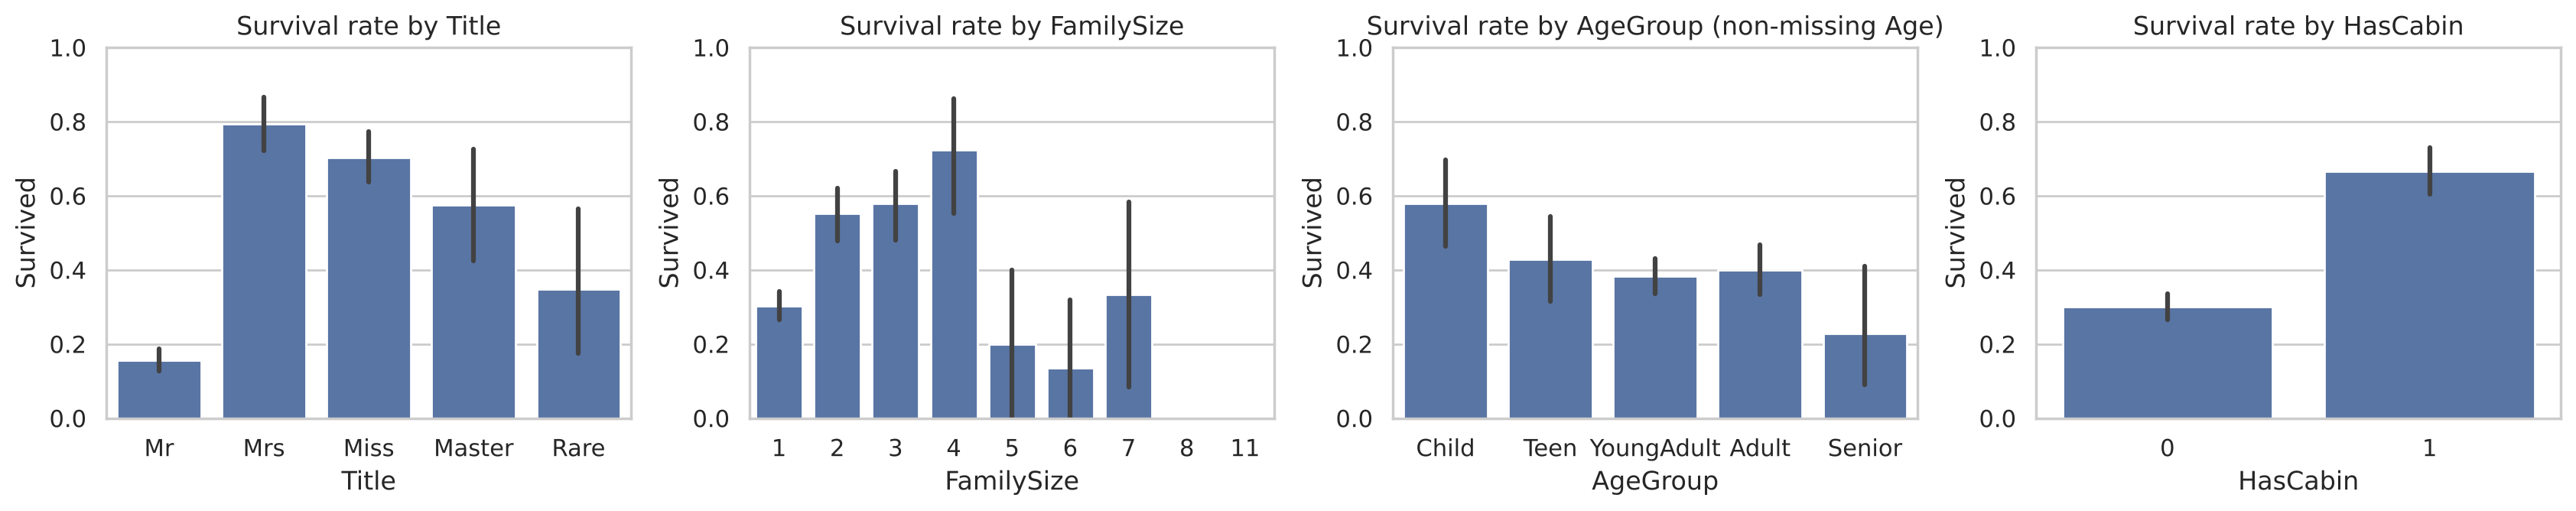

In [12]:
dfe["AgeGroup"] = pd.cut(dfe["Age"], bins=[0, 12, 18, 35, 60, 200],
                         labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
sns.barplot(data=dfe, x="Title", y="Survived", ax=axes[0], order=["Mr", "Mrs", "Miss", "Master", "Rare"])
sns.barplot(data=dfe, x="FamilySize", y="Survived", ax=axes[1])
sns.barplot(data=dfe, x="AgeGroup", y="Survived", ax=axes[2])
sns.barplot(data=dfe, x="HasCabin", y="Survived", ax=axes[3])
for ax, t in zip(axes, ["Title", "FamilySize", "AgeGroup (non-missing Age)", "HasCabin"]):
    ax.set_title(f"Survival rate by {t}"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f"{FIG}/06_barplot_features.png", dpi=150); plt.show()

In [13]:
for c in ["Title", "FamilySize", "IsAlone", "HasCabin", "AgeGroup"]:
    print(dfe.groupby(c, observed=True)["Survived"].agg(["mean", "count"]).round(3), "\n")
print("Age missing -> survival rate:", round(df[df.Age.isna()].Survived.mean(), 3),
      "| Age present ->", round(df[df.Age.notna()].Survived.mean(), 3))
print("duplicated rows:", df.duplicated().sum())

         mean  count
Title               
Master  0.575     40
Miss    0.703    185
Mr      0.157    517
Mrs     0.794    126
Rare    0.348     23 

             mean  count
FamilySize              
1           0.304    537
2           0.553    161
3           0.578    102
4           0.724     29
5           0.200     15
6           0.136     22
7           0.333     12
8           0.000      6
11          0.000      7 

          mean  count
IsAlone              
0        0.506    354
1        0.304    537 

           mean  count
HasCabin              
0         0.300    687
1         0.667    204 

             mean  count
AgeGroup                
Child       0.580     69
Teen        0.429     70
YoungAdult  0.383    358
Adult       0.400    195
Senior      0.227     22 

Age missing -> survival rate: 0.294 | Age present -> 0.406
duplicated rows: 0
